In [5]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\jjksa\MedicalInsurance
['.ipynb_checkpoints', 'insurance.csv', 'Simple_and_Multiple_Linear_Regression.ipynb']


In [6]:
import pandas as pd

df = pd.read_csv("insurance.csv")

print(df.head())
print(df.columns)
print(df.shape)

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')
(1338, 7)


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [9]:
# Step 1: Load the dataset
df = pd.read_csv("insurance.csv")

In [10]:
print("Dataset:")
print(df.head())

Dataset:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [11]:
# Step 2: Select input and output variables

# Simple Linear Regression
X_simple = df[["age"]]

# Multiple Linear Regression
X_multiple = pd.get_dummies(
    df[["age", "bmi", "children", "sex", "smoker", "region"]],
    drop_first=True,
    dtype=int
)

In [12]:
y = df["charges"]

# Step 3: Split the data
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)


In [13]:
# Step 4: Simple Linear Regression
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, simple_predictions)
))


--- Simple Linear Regression ---
Intercept: 3876.928684191691
Coefficient: 240.59655978877493
R2 Score: 0.12408973539501944
RMSE: 11661.21595205864


In [14]:
# Step 5: Multiple Linear Regression
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))


--- Multiple Linear Regression ---
Intercept: -11931.219050326692
Coefficients: [ 2.56975706e+02  3.37092552e+02  4.25278784e+02 -1.85916916e+01
  2.36511289e+04 -3.70677326e+02 -6.57864297e+02 -8.09799354e+02]
R2 Score: 0.7835929767120723
RMSE: 5796.2846592762735


In [15]:
# Step 6: Predict insurance charges for a new person

# Simple Regression: age = 30
new_person_simple = pd.DataFrame({"age": [30]})

print("\nPredicted Charges using Simple Regression:",
      simple_model.predict(new_person_simple)[0])


Predicted Charges using Simple Regression: 11094.825477854938


In [16]:
# Multiple Regression: age, BMI, children and categories
new_person = pd.DataFrame({
    "age": [30],
    "bmi": [25.5],
    "children": [1],
    "sex": ["female"],
    "smoker": ["no"],
    "region": ["southeast"]
})

In [17]:
new_person_encoded = pd.get_dummies(
    new_person,
    drop_first=True,
    dtype=int
)

new_person_encoded = new_person_encoded.reindex(
    columns=X_multiple.columns,
    fill_value=0
)

print("Predicted Charges using Multiple Regression:",
      multiple_model.predict(new_person_encoded)[0])

Predicted Charges using Multiple Regression: 4799.190982827315


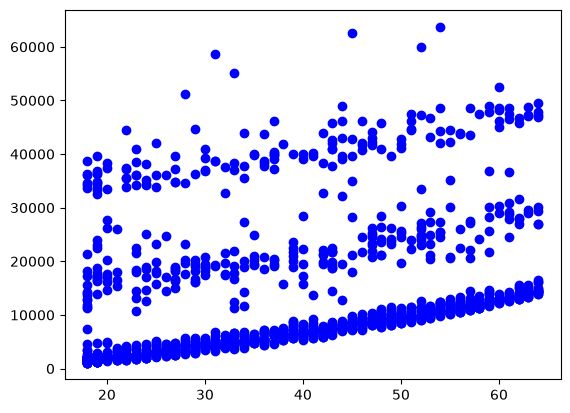

In [18]:
# Step 7: Plot Simple Linear Regression
plt.scatter(
    df["age"], df["charges"],
    color="blue", label="Actual Charges"
)

sorted_indices = np.argsort(df["age"].values)

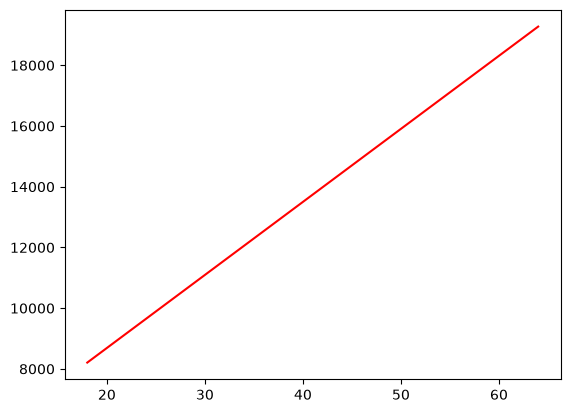

In [19]:
plt.plot(
    df["age"].iloc[sorted_indices],
    simple_model.predict(X_simple.iloc[sorted_indices]),
    color="red", label="Regression Line"
)

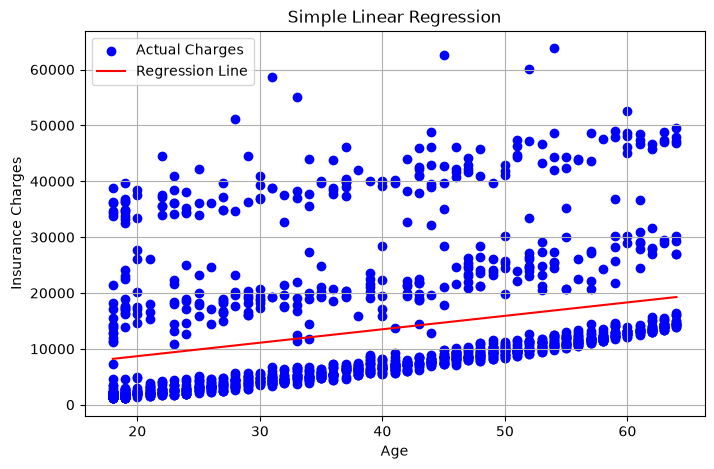

In [22]:
# Plot Simple Linear Regression

plt.figure(figsize=(8, 5))

plt.scatter(
    df["age"],
    df["charges"],
    color="blue",
    label="Actual Charges"
)

plt.plot(
    np.sort(df["age"].values),
    simple_model.predict(
        pd.DataFrame({"age": np.sort(df["age"].values)})
    ),
    color="red",
    label="Regression Line"
)

plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.title("Simple Linear Regression")
plt.legend(["Actual Charges", "Regression Line"])
plt.grid(True)
plt.show()